In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.decomposition import PCA

FOLDER = Path(r"C:\Users\ncollins\OneDrive - Dublin City University\Eurostat_EUDA_datasets")
data = {f.stem: pd.read_csv(f, encoding="utf-8-sig", low_memory=False) for f in FOLDER.glob("*.csv")}

FOCUS = {"Ireland": "#1BAF7A", "Portugal": "#2A78D6", "Netherlands": "#EB6834"}
NOT_COUNTRIES = ["European Union", "EU, Türkiye and Norway"]

In [2]:
def euda(file, column, name):
    """One column from an EUDA annex table -> Country, name."""
    d = data[file][["Country", column]].rename(columns={column: name})
    d[name] = pd.to_numeric(d[name], errors="coerce")
    return d[~d["Country"].isin(NOT_COUNTRIES)]

def eurostat(file, name, **filters):
    """Latest value per country from a Eurostat file, after filtering."""
    d = data[file]
    for col, value in filters.items():
        d = d[d[col] == value]
    d = d.sort_values("TIME_PERIOD").groupby("geo").tail(1)   # latest year
    return d[["Geopolitical entity (reporting)", "OBS_VALUE"]].set_axis(["Country", name], axis=1)

# Build one table: one row per country, one column per indicator
parts = [
    euda("edr2026-annex-table-6-other-indicators",
         "Drug-induced deaths - Cases per million population - Aged 15-64", "deaths"),
    euda("edr2026-annex-table-2a-cocaine-prevalence",
         "General population surveys - last 12 months, young adults (15-34)", "cocaine"),
    euda("edr2026-annex-table-5a-cannabis-prevalence",
         "General population surveys - last 12 months, young adults (15-34)", "cannabis"),
    eurostat("eurostat-ilc_di03-mean-median-income", "income",
             statinfo="MED_EI", unit="PPS", age="TOTAL", sex="T"),
    eurostat("eurostat-ilc_mdsd11-severe-material-social-deprivation", "deprivation",
             unit="PC", age="TOTAL", sex="T"),
    eurostat("eurostat-ilc_di12-income-inequality-gini", "gini", age="TOTAL"),
]
df = parts[0]
for p in parts[1:]:
    df = df.merge(p, on="Country", how="inner")
df = df.dropna().set_index("Country")
print(len(df), "countries with every indicator")
print(df.loc[list(FOCUS)])

29 countries with every indicator
             deaths  cocaine  cannabis  income  deprivation  gini
Country                                                          
Ireland        78.0      5.0      14.8   25449          5.2  27.2
Portugal       15.0      0.5       4.9   16634          4.3  30.9
Netherlands    28.0      5.3      15.4   29714          2.6  25.9


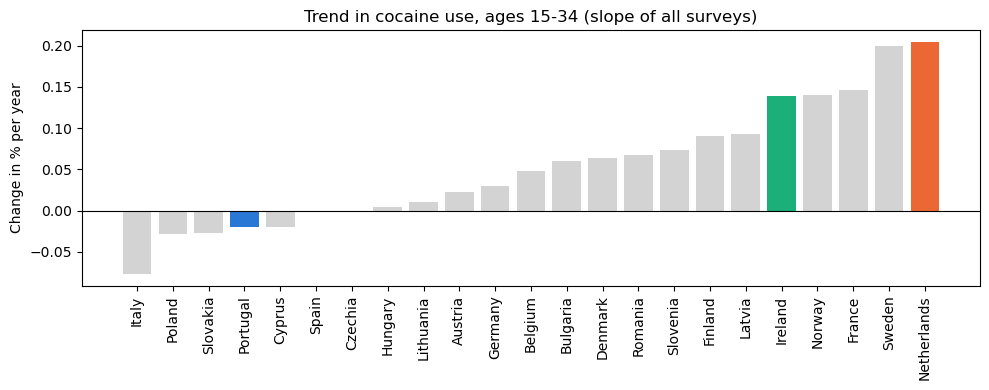

Ireland        0.139
Portugal      -0.020
Netherlands    0.205
dtype: float64


In [3]:
trends = data["edr2026-gps-trends-table-1"]

def slopes(substance):
    s = trends[(trends["Substance"] == substance) & (trends["Recall period"] == "Last year") &
               (trends["Age"] == "Young adults (15-34)") & (trends["Geographical scope"] == "National")]
    years = [c for c in s.columns if c.isdigit()]
    long = s.melt(id_vars="Country", value_vars=years, var_name="Year", value_name="Value")
    long["Year"] = long["Year"].astype(int)
    long["Value"] = pd.to_numeric(long["Value"], errors="coerce")
    long = long.dropna()
    result = {}
    for country, g in long.groupby("Country"):
        if len(g) >= 3:                                   # need 3+ surveys for a fair slope
            result[country] = np.polyfit(g["Year"], g["Value"], 1)[0]
    return pd.Series(result).sort_values()

cocaine_slope = slopes("Cocaine")
colours = [FOCUS.get(c, "lightgrey") for c in cocaine_slope.index]
plt.figure(figsize=(10, 4))
plt.bar(cocaine_slope.index, cocaine_slope.values, color=colours)
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=90)
plt.ylabel("Change in % per year")
plt.title("Trend in cocaine use, ages 15-34 (slope of all surveys)")
plt.tight_layout(); plt.show()
print(cocaine_slope.loc[[c for c in FOCUS if c in cocaine_slope.index]].round(3))

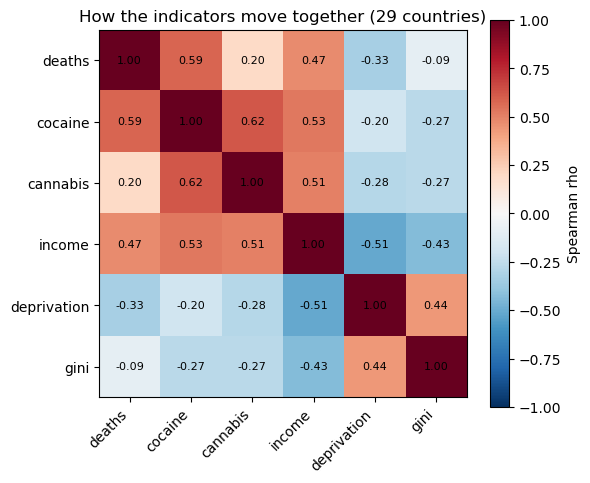

In [4]:
corr = df.corr(method="spearman")
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Spearman rho")
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("How the indicators move together (29 countries)")
plt.tight_layout(); plt.show()


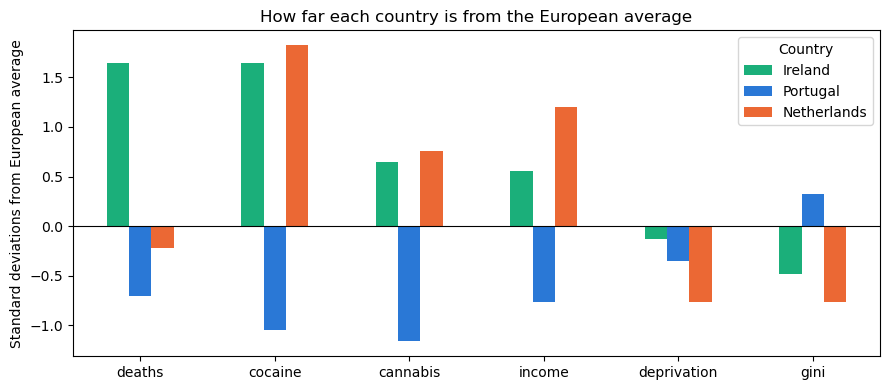

In [5]:
z = (df - df.mean()) / df.std()          # 0 = average, +1 = one std dev above
z.loc[list(FOCUS)].T.plot(kind="bar", color=list(FOCUS.values()), figsize=(9, 4))
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Standard deviations from European average")
plt.title("How far each country is from the European average")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

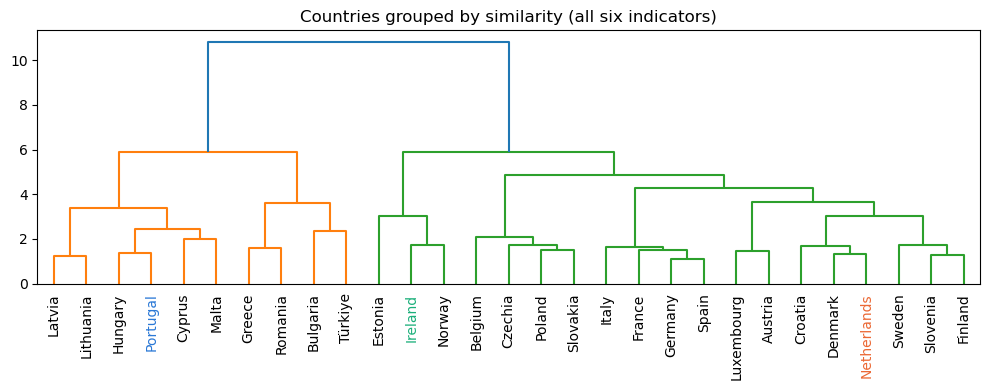

         deaths  cocaine  cannabis   income  deprivation  gini
cluster                                                       
1          27.5      0.8       6.4  18443.5          4.9  32.0
2          13.8      1.0       4.5  13179.8         14.7  35.1
3          88.3      5.1      13.4  25465.7          3.8  27.3
4          31.1      2.6      14.4  24443.2          4.2  27.4
Country
Ireland        3
Portugal       1
Netherlands    4
Name: cluster, dtype: int32


In [6]:
links = linkage(z, method="ward")             # uses the z-scores so units don't matter
plt.figure(figsize=(10, 4))
dendrogram(links, labels=z.index.tolist(), leaf_rotation=90)
for label in plt.gca().get_xticklabels():     # colour our three countries' names
    label.set_color(FOCUS.get(label.get_text(), "black"))
plt.title("Countries grouped by similarity (all six indicators)")
plt.tight_layout(); plt.show()

df["cluster"] = fcluster(links, t=4, criterion="maxclust")   # cut the tree into 4 groups
print(df.groupby("cluster").mean().round(1))
print(df.loc[list(FOCUS), "cluster"])

Variance explained: [0.49 0.18]
     deaths  cocaine  cannabis  income  deprivation  gini
PC1    0.34     0.44      0.41    0.45        -0.44 -0.35
PC2    0.65     0.45     -0.11   -0.17         0.27  0.51


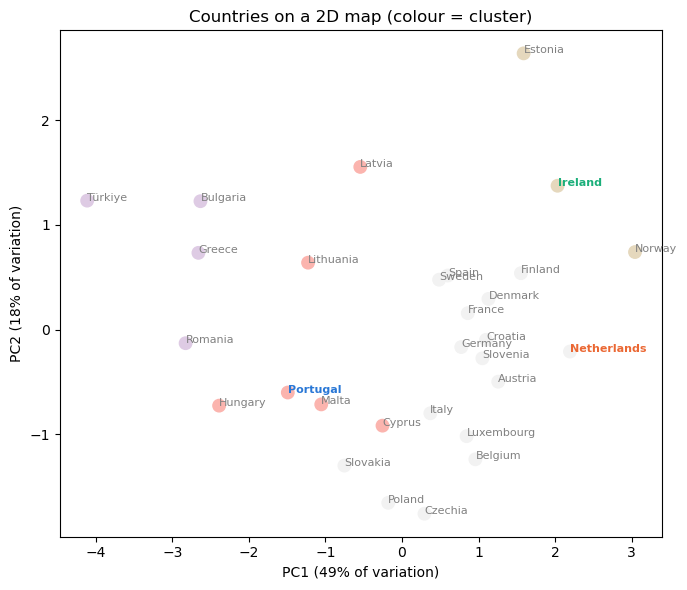

In [7]:
pca = PCA(n_components=2)
xy = pca.fit_transform(z)
print("Variance explained:", pca.explained_variance_ratio_.round(2))
print(pd.DataFrame(pca.components_, columns=z.columns, index=["PC1", "PC2"]).round(2))

plt.figure(figsize=(7, 6))
plt.scatter(xy[:, 0], xy[:, 1], c=df["cluster"], cmap="Pastel1", s=80)
for (x, y), country in zip(xy, z.index):
    plt.annotate(country, (x, y), fontsize=8,
                 color=FOCUS.get(country, "grey"), weight="bold" if country in FOCUS else "normal")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
plt.title("Countries on a 2D map (colour = cluster)")
plt.tight_layout(); plt.show()

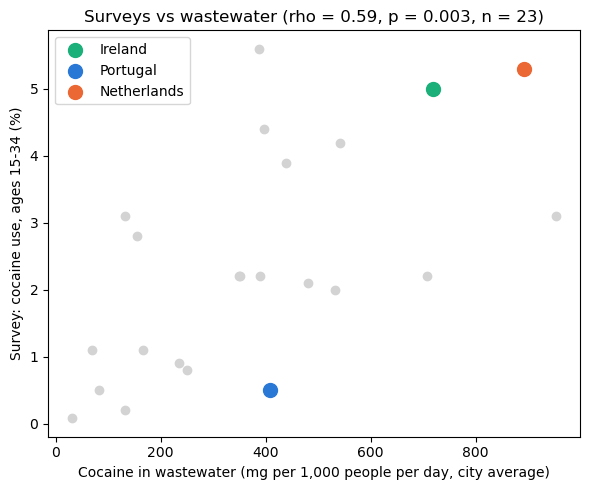

In [8]:
ww = data["edr2026-ww-changes-with-previous-measure"]
ww = ww[ww["Substance targeted"] == "cocaine"].groupby("Country")["Current value"].mean()
codes = data["eurostat-ilc_di12-income-inequality-gini"][["geo", "Geopolitical entity (reporting)"]]
ww.index = ww.index.map(dict(codes.drop_duplicates().values))   # "IE" -> "Ireland"
both = df[["cocaine"]].join(ww.rename("wastewater"), how="inner")

rho, p = spearmanr(both["cocaine"], both["wastewater"])
plt.figure(figsize=(6, 5))
plt.scatter(both["wastewater"], both["cocaine"], color="lightgrey")
for country, colour in FOCUS.items():
    if country in both.index:
        plt.scatter(both.loc[country, "wastewater"], both.loc[country, "cocaine"], color=colour, s=100, label=country)
plt.xlabel("Cocaine in wastewater (mg per 1,000 people per day, city average)")
plt.ylabel("Survey: cocaine use, ages 15-34 (%)")
plt.title(f"Surveys vs wastewater (rho = {rho:.2f}, p = {p:.3f}, n = {len(both)})")
plt.legend(); plt.tight_layout(); plt.show()

In [9]:
pairs = [("income", "cocaine"), ("income", "cannabis"), ("income", "deaths"),
         ("deprivation", "deaths"), ("gini", "deaths")]
rng = np.random.default_rng(42)
rows = []
for x, y in pairs:
    rho, p = spearmanr(df[x], df[y])
    # Leave-one-out: drop each country in turn, recalculate rho
    loo = [spearmanr(df.drop(c)[x], df.drop(c)[y])[0] for c in df.index]
    # Bootstrap: resample countries 1,000 times
    boot = [spearmanr(*df.sample(len(df), replace=True, random_state=rng)[[x, y]].T.values)[0]
            for _ in range(1000)]
    rows.append({"pair": f"{x} vs {y}", "rho": rho, "p": p,
                 "LOO min": min(loo), "LOO max": max(loo),
                 "95% CI low": np.percentile(boot, 2.5), "95% CI high": np.percentile(boot, 97.5),
                 "passes Bonferroni": p < 0.05 / len(pairs)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                 pair    rho     p  LOO min  LOO max  95% CI low  95% CI high  passes Bonferroni
    income vs cocaine  0.529 0.003    0.477    0.614       0.156        0.765               True
   income vs cannabis  0.507 0.005    0.462    0.579       0.131        0.766               True
     income vs deaths  0.470 0.010    0.413    0.542       0.106        0.742              False
deprivation vs deaths -0.334 0.077   -0.402   -0.260      -0.632        0.038              False
       gini vs deaths -0.092 0.636   -0.171   -0.012      -0.455        0.337              False
